# 7.2 The Hugging Face Ecosystem (Essentials)

**Module 7 · Note 2**

In Note 7.1 we downloaded two pretrained models by name, and the library quietly did a lot for us. It found the model on a website, decided which files to fetch, stored them on our disk, rebuilt the architecture from a configuration, loaded the weights and prepared a tokeniser. To use pretrained models confidently, and to work out what went wrong when something fails, you need to know what each of those pieces is and where it lives.

Almost all of that machinery comes from one company and its open-source projects: **Hugging Face**. Its website, the **Hub**, is where most openly shared models and datasets are published, and its Python libraries are the standard way to load and use them. This note is a guided tour of that ecosystem: the essentials you need for the rest of Modules 7 and 8, not every feature.

**Key question:** *What does the Hugging Face ecosystem give us, and what exactly are we downloading when we load a model by name?*

**By the end of this note you will be able to:**
- describe how the Hub, the local cache and the three core libraries fit together;
- read a model repository's file list and say what each file is for, and which ones are actually downloaded;
- read a model card's metadata, evaluation claims and limitations, and test a claim yourself;
- use Datasets to load, inspect, filter, tokenise and batch a dataset;
- explain what the Tokenizers library does, and show why a model and its tokeniser must be used together;
- check a model's licence and access restrictions before relying on it.

**Before you start:** read Note 7.1 first. You will need the idea of a configuration plus weights (7.1, Section 6), tokens and subword tokenisation (Notes 5.3 and 6.2), and PyTorch's `DataLoader` from Module 2.

### Setup

The setup cell imports the libraries and prints their versions. Hugging Face's libraries change quickly, so when you compare your results with someone else's, versions are the first thing to check. The same harmless warnings as in Note 7.1 appear here (the TqdmWarning about IProgress, the unauthenticated-request message, and on a Mac a few `W…` lines when the libraries load).

In [1]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import transformers, datasets, tokenizers, huggingface_hub
from huggingface_hub import HfApi, ModelCard, hf_hub_download, scan_cache_dir
from datasets import load_dataset
from transformers import AutoConfig, AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
for lib in (transformers, datasets, tokenizers, huggingface_hub):
    print(f"{lib.__name__:<16} {lib.__version__}")

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu
transformers     5.20.1
datasets         5.1.0
tokenizers       0.23.3
huggingface_hub  1.33.0


## 1. The Big Picture: Where Hugging Face Fits in AI Engineering

Let's begin with the whole workflow in three short cells. First, we ask for a model by its **repository name**, an owner and a model name separated by a slash, just like a GitHub project.

In [2]:
SST2 = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"   # a repository name on the Hub

tokenizer = AutoTokenizer.from_pretrained(SST2)                               # Tokenizers library, via Transformers
model = AutoModelForSequenceClassification.from_pretrained(SST2).to(device).eval()  # Transformers library

W1017 12:52:03.618000 72510 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 12:52:03.715000 72510 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 12:52:03.735000 72510 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 12484.83it/s]

Two lines, two libraries. `AutoTokenizer` gives us the tokeniser; its fast text-splitting engine comes from the **Tokenizers** library. `AutoModelForSequenceClassification` comes from **Transformers**, and so does the code that builds the network. Both looked up the name on the **Hub**, downloaded what they needed, and stored it. Now we use them:

In [3]:
enc = tokenizer("A gripping, beautifully shot film.", return_tensors="pt").to(device)   # text -> token IDs
with torch.no_grad():
    probs = model(**enc).logits.softmax(dim=-1)[0]                  # (2,) class probabilities
print({model.config.id2label[i]: round(p.item(), 3) for i, p in enumerate(probs)})

{'NEGATIVE': 0.0, 'POSITIVE': 1.0}


The model is sure this one is positive: 1.0 against 0.0, rounded. Where did the downloaded files go?

In [4]:
cache = huggingface_hub.constants.HF_HUB_CACHE                       # where downloads are stored
print("local cache folder ends in:", os.path.join(*cache.split(os.sep)[-2:]))

local cache folder ends in: huggingface/hub


Every download is stored in a **local cache**, a folder that by default is `~/.cache/huggingface/hub` in your home directory. (You can move it by setting the `HF_HOME` environment variable, which is what was done when these notes were built.) The second time you load the same model, nothing is downloaded: the library finds the files in the cache.

That is the whole ecosystem in one picture:
- the **Hub** stores and publishes models and datasets, with their documentation;
- the **libraries** (Transformers, Datasets and Tokenizers, with a helper library called `huggingface_hub` underneath) fetch them and turn them into working Python objects;
- the **cache** keeps local copies so you download each file only once;
- **your code** sits on top and decides what to do with the model.

> 🖼 *IMAGE 7.2.1 — The Hugging Face Ecosystem.* A layered diagram on a white background. Top layer: a wide rounded rectangle labelled "Hugging Face Hub (website)" containing three small icons with captions: "model repositories", "dataset repositories", "model cards". A downward arrow labelled "download once (huggingface_hub)" leads to a cylinder labelled "local cache · ~/.cache/huggingface/hub". From the cache, three arrows lead up into a middle layer of three side-by-side boxes: "Transformers: models, configs, pipelines", "Datasets: load, filter, map, batch", "Tokenizers: fast text → token IDs". Bottom layer: a box labelled "your code · e.g. sentiment = model(tokenizer(text))". Colours: Hub and models in blue, datasets in green, tokenizers in purple, your code in orange. Takeaway: the Hub publishes, the cache stores, the libraries load, and your code decides.

> **Key terms**
> - **Hugging Face Hub:** a website hosting openly shared models, datasets and demos, each in its own repository.
> - **Repository name:** the `owner/name` identifier of a Hub repository, such as `distilbert/distilbert-base-uncased-finetuned-sst-2-english`.
> - **Local cache:** the folder where downloaded files are kept so they are not downloaded again.
> - **Transformers, Datasets, Tokenizers:** Hugging Face's main libraries, for models, data and text splitting respectively.

The next section looks at the top layer: what is actually stored in a repository.

## 2. The Hub, Model Repositories and Model Cards

### 2.1 What is in a repository?

A **model repository** is a folder of files with a history, much like a code repository on GitHub. The `huggingface_hub` library can list a repository's files and their sizes without downloading anything.

In [5]:
api = HfApi()
info = api.model_info(SST2, files_metadata=True)                     # metadata only, no downloads
print(f"task: {info.pipeline_tag} | library: {info.library_name}")
print(f"{len(info.siblings)} files in the repository:")
for f in info.siblings:
    print(f"  {f.rfilename:<28} {f.size / 1e6:9.3f} MB")

task: text-classification | library: transformers
17 files in the repository:
  .gitattributes                   0.000 MB
  README.md                        0.011 MB
  config.json                      0.001 MB
  map.jpeg                         0.082 MB
  model.safetensors              267.833 MB
  onnx/added_tokens.json           0.000 MB
  onnx/config.json                 0.001 MB
  onnx/model.onnx                267.956 MB
  onnx/special_tokens_map.json     0.000 MB
  onnx/tokenizer.json              0.711 MB
  onnx/tokenizer_config.json       0.001 MB
  onnx/vocab.txt                   0.232 MB
  pytorch_model.bin              267.844 MB
  rust_model.ot                  267.846 MB
  tf_model.h5                    267.950 MB
  tokenizer_config.json            0.000 MB
  vocab.txt                        0.232 MB


The repository has 17 files, and they fall into four groups.

- **The configuration:** `config.json`, the architecture blueprint you read in Note 7.1.
- **The weights, five times over:** `model.safetensors`, `pytorch_model.bin`, `tf_model.h5`, `rust_model.ot` and `onnx/model.onnx` are each about 268 MB (267.833 MB, 267.844 MB, 267.950 MB, 267.846 MB and 267.956 MB). They hold the same learned numbers, saved in formats for different software: the safe format we used in 7.1, the older PyTorch format, TensorFlow's format, a Rust library's format, and ONNX, a format for running models outside Python. The `onnx/` folder also has its own copy of the tokeniser files, so that version works without the rest of the repository.
- **The tokeniser:** `vocab.txt` lists the vocabulary, one token per line, and `tokenizer_config.json` holds tokeniser settings.
- **Documentation:** `README.md` is the **model card**, and `map.jpeg` is a picture the card displays. `.gitattributes` is a bookkeeping file for the version-control system.

Transformers does not download all of this. It picks only the files it needs for PyTorch, and prefers `.safetensors` when a repository offers it. We'll check exactly what landed on our disk at the end of this section.

### 2.2 The model card

The **model card** is the repository's `README.md`: a document describing what the model is, how it was trained, what it is for and where it fails. The top of the file holds machine-readable **metadata**, and the rest is written for people.

In [6]:
card = ModelCard.load(SST2)                                           # downloads README.md, the model card
meta = card.data.to_dict()
print("metadata:", {k: v for k, v in meta.items() if k != "model-index"})
print("\nsection headings:")
for line in card.text.splitlines():
    if line.startswith("#"):
        print("  " + line)

metadata: {'datasets': ['sst2', 'glue'], 'language': 'en', 'license': 'apache-2.0'}

section headings:
  # DistilBERT base uncased finetuned SST-2
  ## Table of Contents
  ## Model Details
  ## How to Get Started With the Model
  ## Uses
  #### Direct Use
  #### Misuse and Out-of-scope Use
  ## Risks, Limitations and Biases
  # Training
  #### Training Data
  #### Training Procedure
  ###### Fine-tuning hyper-parameters


The metadata says the model was trained on `sst2` (the dataset is also part of a benchmark collection called `glue`), works on English (`en`), and is released under the `apache-2.0` licence (Section 4). The headings show a well-organised card: details, how to use it, intended uses and misuses, risks, and how it was trained.

Cards can also declare evaluation results in a structured block called `model-index`. Here are its accuracy entries:

In [7]:
for result in meta["model-index"][0]["results"]:                      # evaluation results declared in the card
    ds = result["dataset"]
    for m in result["metrics"]:
        if m.get("type") == "accuracy":
            print(f"dataset: {ds.get('name')} | split: {ds.get('split')} | accuracy {m.get('value'):.4f}")

dataset: glue | split: validation | accuracy 0.9106
dataset: sst2 | split: train | accuracy 0.9886


Two numbers, and only one of them is useful. On the `glue` validation split, a set of SST-2 sentences the model did not train on, the card reports an accuracy of 0.9106. It also reports 0.9886 on its own `sst2` training split. A model's score on the data it was trained on says almost nothing about new data, as you saw when diagnosing overfitting in Module 3, so ignore that number. Note too that both numbers are on SST-2's short sentences, not on reviews like IMDb's. Note 7.3 measures what that means in practice.

The most valuable part of a good card is often its honest list of problems:

In [8]:
text = card.text
start = text.index("## Risks, Limitations and Biases")
print(text[start:start + 1100])

## Risks, Limitations and Biases

Based on a few experimentations, we observed that this model could produce biased predictions that target underrepresented populations.

For instance, for sentences like `This film was filmed in COUNTRY`, this binary classification model will give radically different probabilities for the positive label depending on the country (0.89 if the country is France, but 0.08 if the country is Afghanistan) when nothing in the input indicates such a strong semantic shift. In this [colab](https://colab.research.google.com/gist/ageron/fb2f64fb145b4bc7c49efc97e5f114d3/biasmap.ipynb), [Aurélien Géron](https://twitter.com/aureliengeron) made an interesting map plotting these probabilities for each country.

<img src="https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-english/resolve/main/map.jpeg" alt="Map of positive probabilities per country." width="500"/>

We strongly advise users to thoroughly probe these aspects on their use-cases in order to evalu

The authors report that the model treats sentences about different countries very differently: 0.89 probability of positive for "This film was filmed in France", but 0.08 for Afghanistan. Nothing in such a sentence says anything good or bad about the film. We will test this claim ourselves in Section 4.

### 2.3 What landed on your computer

Now let's look in the cache for this repository and see which of the 17 files we actually have.

In [9]:
repo = next(r for r in scan_cache_dir().repos if r.repo_id == SST2)
local = sorted(f.file_name for rev in repo.revisions for f in rev.files)
print("files downloaded so far:", local)
print(f"size on disk: {repo.size_on_disk / 1e6:.1f} MB")
path = hf_hub_download(SST2, "config.json")
print("one file's path inside the cache:", path[path.index("models--"):])

files downloaded so far: ['README.md', 'config.json', 'model.safetensors', 'tokenizer_config.json', 'vocab.txt']
size on disk: 268.1 MB


one file's path inside the cache: models--distilbert--distilbert-base-uncased-finetuned-sst-2-english/snapshots/714eb0fa89d2f80546fda750413ed43d93601a13/config.json


We have 5 of the 17 files: the configuration, the safetensors weights, the two tokeniser files and the card (fetched just now, when we read it). That's 268.1 MB rather than more than a gigabyte for all five weight formats. The path shows how the cache is organised: one folder per repository (`models--owner--name`), then a `snapshots` folder with one subfolder per commit (the `714eb0fa…` ID we pinned in Note 7.1), then the files.

> 🖼 *IMAGE 7.2.2 — Anatomy of a Model Repository.* On a white background, a large folder titled "distilbert-base-uncased-finetuned-sst-2-english (17 files)" containing four labelled groups drawn as clusters of file cards. Group "blueprint": one small card "config.json". Group "weights (same numbers, five formats)": five large blue cards of equal size, each labelled with its format and "≈268 MB": "model.safetensors · PyTorch (safe)", "pytorch_model.bin · PyTorch (older)", "tf_model.h5 · TensorFlow", "rust_model.ot · Rust", "onnx/model.onnx · ONNX". Group "tokeniser" in purple: "vocab.txt", "tokenizer_config.json". Group "documentation": "README.md (model card)", "map.jpeg". A green tick and the label "downloaded by Transformers" appear on config.json, model.safetensors, vocab.txt, tokenizer_config.json and README.md only; the other weight cards are faded. Caption under the folder: "5 files, 268.1 MB on disk". Takeaway: a repository holds more than you need, and the library fetches only the files for your framework.

> **Key terms**
> - **Model repository:** a Hub folder holding a model's configuration, weights, tokeniser files and documentation, with version history.
> - **Model card:** the repository's `README.md`, describing the model, its training, intended uses, limitations and evaluation.
> - **Card metadata:** the machine-readable header of a model card, with fields such as `license`, `language`, `datasets` and `model-index`.
> - **ONNX:** a file format for running models outside the framework that trained them.

> **Common mistake:** quoting a model card's benchmark number as if it applied to your data. A card's numbers describe *its* evaluation data; this card's are for short SST-2 sentences. Measure on your own data before relying on them.

> **Check yourself 1.** The repository holds five copies of the weights, but loading the model downloaded only one. Why is that a good design, and which file would it have chosen if `model.safetensors` were missing?

> **Check yourself 2.** The card reports an accuracy of 0.9886 on `sst2` train and 0.9106 on `glue` validation. Which would you put in a report to your manager, and why?

With the Hub covered, the next section turns to the libraries that use it.

## 3. The Core Libraries: Transformers, Datasets, Tokenizers

### 3.1 Transformers: one interface for many architectures

The Transformers library contains code for hundreds of model architectures. The **Auto classes** (`AutoConfig`, `AutoTokenizer`, `AutoModel…`) save you from knowing which class each repository needs: they read the repository's `config.json`, look at its `model_type`, and build the matching class. Downloading only the configuration (a few kilobytes) is enough to see this:

In [10]:
repos = [SST2, "distilbert/distilgpt2", "sentence-transformers/all-MiniLM-L6-v2", "openai/clip-vit-base-patch32"]
for r in repos:
    cfg = AutoConfig.from_pretrained(r)                               # downloads config.json only
    print(f"{r:<58} model_type: {cfg.model_type:<11} architectures: {cfg.architectures}")

distilbert/distilbert-base-uncased-finetuned-sst-2-english model_type: distilbert  architectures: ['DistilBertForSequenceClassification']


distilbert/distilgpt2                                      model_type: gpt2        architectures: ['GPT2LMHeadModel']


sentence-transformers/all-MiniLM-L6-v2                     model_type: bert        architectures: ['BertModel']


openai/clip-vit-base-patch32                               model_type: clip        architectures: ['CLIPModel']


Four repositories, four different architectures: DistilBERT, GPT-2, BERT and CLIP. Yet the same line of code, `AutoConfig.from_pretrained(name)`, handled all of them. The `architectures` field records which class the weights were saved from: a sequence classifier, a language model with a word-prediction head (`GPT2LMHeadModel`), a bare BERT body, and a combined image–text model. The rest of Module 7 loads all four. Note 7.4 covers the Auto classes for loading models in detail.

### 3.2 Datasets: data that doesn't fill your memory

The **Datasets** library does for data what Transformers does for models: it downloads datasets from the Hub by name, and gives them a common interface. We'll load IMDb's official train and test files, as in Note 7.1.

In [11]:
imdb = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                    data_files={"train": "plain_text/train-*.parquet",
                                "test": "plain_text/test-*.parquet"})
print(imdb)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
})


The result is a `DatasetDict`: a dictionary of splits, each a `Dataset` with named columns (**features**) and a number of rows. Each split has 25000 reviews. Let's look inside the training split:

In [12]:
train = imdb["train"]
print("features:", train.features)
print("labels:", np.bincount(list(train["label"])))
row = train[0]                                                        # one row is a plain dictionary
print(row["label"], "|", row["text"][:240])

features: {'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}
labels: [12500 12500]
0 | I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefor


The `label` column is a `ClassLabel` with names `neg` and `pos`, stored as 0 and 1, and the split is exactly balanced: 12500 of each. Indexing a row gives a plain Python dictionary. (This first review shows the official files' quirks: no cleaning, and the IMDb split from Note 7.1, with duplicates removed, is built on top of this raw version.)

How does a library handle datasets far larger than memory? It doesn't load them into memory at all:

In [13]:
print("table type:", type(train.data).__name__)
for f in train.cache_files:
    print("backed by:", os.path.basename(f["filename"]), f"| {os.path.getsize(f['filename']) / 1e6:.1f} MB on disk")

table type: MemoryMappedTable
backed by: imdb-train.arrow | 33.4 MB on disk


The table is a `MemoryMappedTable`, backed by a 33.4 MB file on disk in the **Apache Arrow** format, a column-based layout designed for fast reading. **Memory mapping** means the operating system reads parts of the file only when they are needed, so a dataset bigger than your RAM still opens instantly. This is also why the library writes cache files: every operation produces a new Arrow table on disk.

Datasets works best through a few operations that each produce a new dataset. `filter` keeps the rows that pass a test:

In [14]:
short = train.filter(lambda r: len(r["text"].split()) < 30)          # keep reviews under 30 words
print(len(short), "reviews under 30 words, for example:")
for r in short.select(range(3)):
    print(f"  {r['label']} | {r['text']}")

49 reviews under 30 words, for example:
  0 | Unwatchable. You can't even make it past the first three minutes. And this is coming from a huge Adam Sandler fan!!1
  0 | You'd better choose Paul Verhoeven's even if you have watched it.
  0 | Long, boring, blasphemous. Never have I been so glad to see ending credits roll.


Only 49 of the 25000 training reviews are under 30 words. You'll see "Filter" progress bars as these operations run.

`map` applies a function to every row, or with `batched=True`, to batches of rows at a time, which is much faster. The most common use is tokenising. Here we count how many DistilBERT tokens each review needs, *without* cutting any off. Expect one warning, "Token indices sequence length is longer than the specified maximum sequence length…": it is the tokeniser pointing out that some reviews are longer than the model can accept. That's true, and exactly what we want to measure.

In [15]:
lengths = train.map(lambda b: {"n_tokens": [len(ids) for ids in tokenizer(b["text"])["input_ids"]]},
                    batched=True, remove_columns=["text"])            # tokens per review, no truncation
n = np.array(lengths["n_tokens"])
print(f"tokens per review: median {np.median(n):.0f} | longest {n.max()} | over 256: {(n > 256).mean():.1%} | over 512: {(n > 512).mean():.1%}")

tokens per review: median 233 | longest 3127 | over 256: 44.3% | over 512: 14.8%


The median review is 233 tokens long, the longest is 3127, and 44.3% of reviews are over 256 tokens, with 14.8% over 512, the most DistilBERT can read at once. (These are raw reviews; the `<br />` tags still in them add a few tokens each.) The histogram shows the long tail:

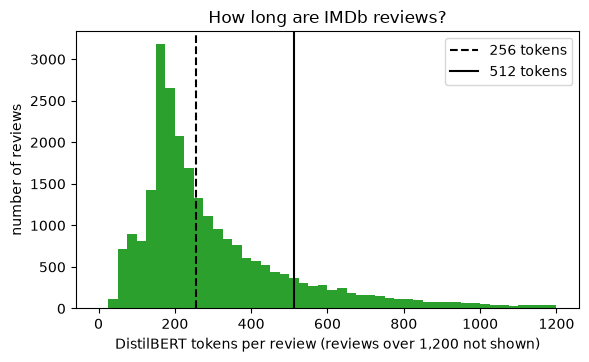

In [16]:
plt.figure(figsize=(6.5, 3.6))
plt.hist(n, bins=np.arange(0, 1201, 25), color="tab:green")
for limit, style in [(256, "--"), (512, "-")]:
    plt.axvline(limit, color="black", ls=style, label=f"{limit} tokens")
plt.xlabel("DistilBERT tokens per review (reviews over 1,200 not shown)"); plt.ylabel("number of reviews")
plt.title("How long are IMDb reviews?"); plt.legend(); plt.show()

Most reviews are a few hundred tokens long, but a long tail stretches far past the 512-token limit. Every model in this module has to decide what to do with that tail: cut it off, which is called truncation, or split the review into pieces. Note 7.4 covers the choice; the 256-token setting used in Note 7.1 cuts off a large share of reviews.

To prepare data for a model, we tokenise with truncation and remove the raw text column. We'll use the first 1,000 reviews to keep this quick:

In [17]:
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=256)   # cut to at most 256 tokens

small = train.select(range(1000)).map(tokenize, batched=True, remove_columns=["text"])
print(small)

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1000
})


Each row now holds `input_ids` (the token IDs), an `attention_mask` (Note 7.4) and a `token_type_ids` column we'll explain in a moment. Finally, `set_format("torch")` makes rows come out as PyTorch tensors, and a `DataLoader` batches them, just as in your own training loops. Because reviews have different lengths, the batches need **padding**: a **data collator** is a function that assembles a batch, and `DataCollatorWithPadding` pads each batch to its longest member.

In [18]:
small.set_format("torch")                                             # rows now come out as tensors
loader = torch.utils.data.DataLoader(small, batch_size=8, shuffle=True,
                                     collate_fn=DataCollatorWithPadding(tokenizer),   # pads each batch
                                     generator=torch.Generator().manual_seed(0))
batch = next(iter(loader))
print({k: tuple(v.shape) for k, v in batch.items()})

{'input_ids': (8, 256), 'token_type_ids': (8, 256), 'attention_mask': (8, 256), 'labels': (8,)}


A batch of 8 reviews, each padded to 256 tokens (the length of the longest review in the batch, which hit the truncation limit), plus 8 labels. The collator also renamed `label` to `labels`, the name Transformers models expect when they compute a loss. This dataset is ready for training, which is exactly where Module 8 picks it up.

> 🖼 *IMAGE 7.2.3 — A Dataset Pipeline.* A horizontal sequence of five rounded boxes connected by arrows on a white background, all in green tones. Box 1: "load_dataset('stanfordnlp/imdb') · 25,000 rows · text, label". Box 2: "filter(…) · keep rows that pass a test". Box 3: "map(tokenize, batched=True) · adds input_ids, attention_mask". Box 4: "set_format('torch') · rows become tensors". Box 5: "DataLoader + DataCollatorWithPadding · batches of shape (8, 256)". Underneath the first three boxes, a grey strip labelled "each step writes a new Arrow table to disk, memory-mapped, not loaded into RAM". Takeaway: Datasets turns raw files into model-ready batches through a chain of simple, cached steps.

> **Key terms**
> - **Dataset / DatasetDict:** a table of examples with named columns / a dictionary of such tables, one per split.
> - **Features:** the named, typed columns of a dataset, such as `text` (a string) and `label` (a class label).
> - **Apache Arrow:** a column-based file format for fast reading of large tables.
> - **Memory mapping:** reading a file on disk as if it were in memory, fetching only the parts that are used.
> - **`map` and `filter`:** Datasets operations that transform every row, or keep only some rows, producing a new dataset.
> - **Data collator:** a function that combines individual examples into a batch, for example by padding them to equal length.

> **Check yourself 3.** A colleague tries to load a 200 GB text dataset on a laptop with 16 GB of RAM using Datasets, and expects it to crash. Why might it not?

### 3.3 Tokenizers: fast, and specific to each model

Which tokeniser did `AutoTokenizer` give us? The answer is a small surprise.

In [19]:
print("tokenizer class:", type(tokenizer).__name__, "| it returns:", tokenizer.model_input_names)
with torch.no_grad():
    with_tt = model(**{k: v.to(device) for k, v in batch.items() if k != "labels"}).logits
    without = model(input_ids=batch["input_ids"].to(device), attention_mask=batch["attention_mask"].to(device)).logits
print("same outputs with and without token_type_ids:", torch.equal(with_tt, without))

tokenizer class: BertTokenizer | it returns: ['input_ids', 'token_type_ids', 'attention_mask']


same outputs with and without token_type_ids: True


We asked for DistilBERT's tokeniser and got a `BertTokenizer`. Recall from Section 2.1 that this repository's `tokenizer_config.json` is tiny: it doesn't name a tokeniser class, so the library fell back to the general BERT tokeniser, which works because DistilBERT uses BERT's vocabulary. The BERT tokeniser also produces `token_type_ids`, which BERT uses to tell two sentences in one input apart. DistilBERT doesn't use them, and the check above shows its outputs are identical with or without them. Repositories are not all equally tidy, and knowing what each file does helps you spot why a tokeniser behaves unexpectedly.

The **Tokenizers** library does the actual splitting, in fast compiled code written in Rust. Its most important lesson is one you met in Note 6.2: *a model and its tokeniser are a pair.* Let's tokenise the same sentence with the tokenisers of two different models.

In [20]:
gpt2_tok = AutoTokenizer.from_pretrained("distilbert/distilgpt2")
sample = "Tokenisers don't agree: unbelievably GOOD!"
for name, t in [("DistilBERT", tokenizer), ("distilgpt2", gpt2_tok)]:
    ids = t(sample)["input_ids"]
    print(f"{name:<11} vocabulary {t.vocab_size:,} | {len(ids)} IDs: {ids}")
    print(f"{'':<11} tokens: {t.convert_ids_to_tokens(ids)}")
print("ID 2204 is", repr(tokenizer.decode([2204])), "to DistilBERT and", repr(gpt2_tok.decode([2204])), "to distilgpt2")

DistilBERT  vocabulary 30,522 | 17 IDs: [101, 19204, 17288, 2015, 2123, 1005, 1056, 5993, 1024, 4895, 8671, 2666, 3567, 6321, 2204, 999, 102]
            tokens: ['[CLS]', 'token', '##iser', '##s', 'don', "'", 't', 'agree', ':', 'un', '##bel', '##ie', '##va', '##bly', 'good', '!', '[SEP]']
distilgpt2  vocabulary 50,257 | 9 IDs: [30642, 21572, 836, 470, 4236, 25, 48943, 21090, 0]
            tokens: ['Token', 'isers', 'Ġdon', "'t", 'Ġagree', ':', 'Ġunbelievably', 'ĠGOOD', '!']
ID 2204 is 'good' to DistilBERT and ' benef' to distilgpt2


The same 42-character sentence becomes 17 IDs for DistilBERT and 9 for distilgpt2, and the IDs share nothing. DistilBERT's vocabulary has 30,522 entries and distilgpt2's 50,257. The splits differ too:
- DistilBERT lowercases everything (`GOOD` became `good`), marks the start and end with `[CLS]` and `[SEP]`, and marks word-continuation pieces with `##`: "unbelievably" became five pieces, `un ##bel ##ie ##va ##bly`.
- distilgpt2 keeps capitals, adds no special tokens, and marks a piece that *starts* with a space with `Ġ`. "unbelievably" is a single token in its larger vocabulary.

The last line makes the point directly: ID 2204 is `good` to DistilBERT but a completely different piece of text to distilgpt2. Feeding one model's IDs to the other may not raise any error. It silently produces nonsense.

The difference in algorithm shows when we look inside:

In [21]:
for name, t in [("DistilBERT", tokenizer), ("distilgpt2", gpt2_tok)]:
    backend = t.backend_tokenizer                                     # the Rust object from the Tokenizers library
    print(f"{name:<11} fast: {t.is_fast} | algorithm: {type(backend.model).__name__}")
print("DistilBERT normaliser:", repr(tokenizer.backend_tokenizer.normalizer.normalize_str("Café FÊTE")))

DistilBERT  fast: True | algorithm: WordPiece
distilgpt2  fast: True | algorithm: BPE
DistilBERT normaliser: 'cafe fete'


Both are "fast" tokenisers, backed by the Tokenizers library. DistilBERT uses **WordPiece** and distilgpt2 uses **BPE** (byte-pair encoding, which you built a version of in Note 6.2). Before splitting, DistilBERT's tokeniser runs a **normaliser** that lowercases and strips accents: "Café FÊTE" becomes `'cafe fete'`. This is what "uncased" means in the model's name.

One more feature of fast tokenisers is invaluable when you build applications: **offset mapping**, which records which characters of the original text each token came from.

In [22]:
enc = tokenizer(sample, return_offsets_mapping=True)
for tok, (a, b) in zip(enc.tokens(), enc["offset_mapping"]):
    print(f"{tok:<10} characters {a:>2}-{b:<2} {sample[a:b]!r}")

[CLS]      characters  0-0  ''
token      characters  0-5  'Token'
##iser     characters  5-9  'iser'
##s        characters  9-10 's'
don        characters 11-14 'don'
'          characters 14-15 "'"
t          characters 15-16 't'
agree      characters 17-22 'agree'
:          characters 22-23 ':'
un         characters 24-26 'un'
##bel      characters 26-29 'bel'
##ie       characters 29-31 'ie'
##va       characters 31-33 'va'
##bly      characters 33-36 'bly'
good       characters 37-41 'GOOD'
!          characters 41-42 '!'
[SEP]      characters  0-0  ''


Each token knows its source characters, even after lowercasing: the token `good` maps back to characters 37–41, which read `'GOOD'` in the original. Special tokens like `[CLS]` map to nothing (0–0). Offsets let you highlight words in the original text, for example to show a user which part of a review a model reacted to.

> **Key terms**
> - **Auto classes:** Transformers classes (`AutoConfig`, `AutoTokenizer`, `AutoModel…`) that read a repository's configuration and build the matching class.
> - **Fast tokeniser:** a tokeniser backed by the compiled Tokenizers library.
> - **WordPiece and BPE:** two subword algorithms; WordPiece marks continuation pieces with `##`, GPT-2's BPE marks pieces that begin with a space with `Ġ`.
> - **Normaliser:** the step before splitting that cleans text, for example by lowercasing and removing accents.
> - **Offset mapping:** for each token, the start and end positions of the characters it came from.

> **Common mistake:** loading a tokeniser from one repository and a model from another. The shapes may match, so nothing crashes, but the IDs mean different things to each, and the predictions are meaningless. Load both from the same repository name.

> **Check yourself 4.** You tokenise a review with distilgpt2's tokeniser and pass the IDs to the SST-2 DistilBERT model. Will you get an error? If not, what will the predictions be worth?

Knowing how to load a model is half the job. The other half is knowing whether you're allowed to, and whether you should.

## 4. Licences, Usage Restrictions and Responsible Selection

### 4.1 Licences

Every model is someone's work, released under some terms. A **licence** states what you may do with it: use it commercially, change it, redistribute it, and under what conditions. On the Hub, the licence is usually declared in the card's metadata, so we can check it in code.

In [23]:
candidates = [SST2, "distilbert/distilbert-base-uncased", "sentence-transformers/all-MiniLM-L6-v2",
              "distilbert/distilgpt2", "openai/clip-vit-base-patch32",
              "meta-llama/Llama-3.2-1B", "google/gemma-2-2b"]
for r in candidates:
    i = api.model_info(r)                                             # metadata only
    licence = i.card_data.get("license") if i.card_data else None
    print(f"{r:<42} licence: {str(licence):<11} gated: {i.gated}")

distilbert/distilbert-base-uncased-finetuned-sst-2-english licence: apache-2.0  gated: False


distilbert/distilbert-base-uncased         licence: apache-2.0  gated: False


sentence-transformers/all-MiniLM-L6-v2     licence: apache-2.0  gated: False


distilbert/distilgpt2                      licence: apache-2.0  gated: False


openai/clip-vit-base-patch32               licence: None        gated: False


meta-llama/Llama-3.2-1B                    licence: llama3.2    gated: manual


google/gemma-2-2b                          licence: gemma       gated: manual


Three different situations appear in this table.

- **A standard open licence.** Four models use `apache-2.0`, a widely used **permissive licence**: you may use, change and redistribute the model, including commercially, as long as you keep the licence and copyright notices.
- **A custom licence with gated access.** `meta-llama/Llama-3.2-1B` and `google/gemma-2-2b` declare their own licences, `llama3.2` and `gemma`. These are custom terms written by the model's publisher, with their own conditions, for example on how the model may be used. Both are **gated** (`manual`): you must sign in, read and accept the terms on the Hub page, and wait for approval before downloading.
- **No declared licence.** `openai/clip-vit-base-patch32` shows `None`.

Let's see what access looks like for a gated model without an account:

In [24]:
try:
    hf_hub_download("meta-llama/Llama-3.2-1B", "config.json")      # a gated repository, without a token
except Exception as e:
    print("download refused:", type(e).__name__, "| HTTP 401 (not authorised):", "401" in str(e))

download refused: GatedRepoError | HTTP 401 (not authorised): True


The Hub refuses: a `GatedRepoError` with HTTP status 401, "not authorised". The metadata was public (we read the licence above), but the files are not until you accept the terms. To use such a model, you would log in with an access token (`hf auth login`) after accepting its terms on the website. Nothing in Modules 7 and 8 needs one.

What about CLIP's missing licence?

In [25]:
clip_card = ModelCard.load("openai/clip-vit-base-patch32")
print("metadata:", clip_card.data.to_dict())
print("lines mentioning a licence:", [l for l in clip_card.text.splitlines() if "licen" in l.lower()])
print("section headings:", [l.strip("# ") for l in clip_card.text.splitlines() if l.startswith("#")])

metadata: {'tags': ['vision'], 'widget': [{'src': 'https://huggingface.co/datasets/mishig/sample_images/resolve/main/cat-dog-music.png', 'candidate_labels': 'playing music, playing sports', 'example_title': 'Cat & Dog'}]}
lines mentioning a licence: []
section headings: ['Model Card: CLIP', 'Model Details', 'Model Date', 'Model Type', 'Documents', 'Use with Transformers', 'Model Use', 'Intended Use', 'Primary intended uses', 'Out-of-Scope Use Cases', 'Data', 'Data Mission Statement', 'Performance and Limitations', 'Performance', 'Limitations', 'Bias and Fairness', 'Feedback', 'Where to send questions or comments about the model']


The card's metadata contains only a tag and a demo-widget setting, and no line of the card mentions a licence at all. That doesn't mean the model is free to use. In most countries, work published without a licence gives you no automatic right to reuse it. The card does say a lot about **intended use**: its headings include "Primary intended uses" and "Out-of-Scope Use Cases". What to do in practice is to look for the licence where the model was originally published (the authors' own code repository), use the model only for the purposes its creators describe, and get advice before building a product on it. Note 7.7 makes this part of a model-selection checklist. In these notes we use CLIP for learning, which is within its stated research purpose.

### 4.2 Responsible selection: test the card's warnings

A licence tells you what you *may* do; the card's limitations tell you what you *should* worry about. Section 2.2's card warned that sentences about different countries get very different sentiment. Let's test that claim with six countries, chosen before running the cell.

In [26]:
countries = ["France", "Afghanistan", "United States", "Nigeria", "India", "Brazil"]   # chosen before running
sentences = [f"This film was filmed in {c}." for c in countries]
enc = tokenizer(sentences, padding=True, return_tensors="pt").to(device)
with torch.no_grad():
    p_pos = model(**enc).logits.softmax(dim=-1)[:, 1]               # (6,) probability of POSITIVE
for c, p in zip(countries, p_pos):
    print(f"P(positive) = {p.item():.3f}  This film was filmed in {c}.")

P(positive) = 0.965  This film was filmed in France.
P(positive) = 0.165  This film was filmed in Afghanistan.
P(positive) = 0.963  This film was filmed in United States.
P(positive) = 0.736  This film was filmed in Nigeria.
P(positive) = 0.986  This film was filmed in India.
P(positive) = 0.969  This film was filmed in Brazil.


The warning holds on today's model. "This film was filmed in Afghanistan." gets a positive probability of 0.165, against 0.965 for France and 0.963 for the United States. Nigeria gets 0.736. The exact values differ from the card's (0.89 and 0.08), which is a good reason to measure rather than copy, but the pattern is the same: the model's judgement of a neutral sentence depends on the country named in it. If this model screened reviews written about films from around the world, some would be judged more harshly purely because of where they were made.

Responsible selection means doing this kind of check as a matter of routine:
1. read the licence and any usage restrictions;
2. read the card's intended uses, out-of-scope uses and limitations;
3. test the warnings that matter for *your* application, on inputs like your users' inputs;
4. record what you found, and decide whether the model is acceptable for the use you have in mind.

> **Key terms**
> - **Licence:** the legal terms under which a model may be used, changed and shared.
> - **Permissive licence:** a licence such as Apache 2.0 that allows broad use, including commercial use, with few conditions.
> - **Custom licence:** terms written by a model's publisher for that model, often with specific use restrictions.
> - **Gated model:** a model whose files can be downloaded only after you sign in and accept its terms.
> - **Intended use / out-of-scope use:** what a model's creators designed it for, and uses they advise against.

> **Common mistake:** treating "downloadable" as "allowed". A model can be public on the Hub and still carry a licence that forbids your use, or carry no licence at all. Check the terms before you build on a model, not after.

> **Check yourself 5.** You find a model on the Hub that scores well on your data, but its card has no licence. Your product is commercial. What do you do?

> **Check yourself 6.** You plan to use the SST-2 model to flag negative product reviews from customers in many countries. Based on Section 4.2, describe one test you would run before deploying it.

## Putting It All Together

Let's reassemble the ecosystem.

When you write `AutoModelForSequenceClassification.from_pretrained("owner/name")`, you are working with every layer at once. The **Hub** stores the model's **repository**: 17 files for the model we studied, including its configuration, the same weights in five formats, its tokeniser files and its **model card**. The `huggingface_hub` library downloads only what your framework needs, 5 files and 268.1 MB here, into the **local cache**, where they are kept by repository and commit. **Transformers** reads the configuration and its Auto classes build the right architecture, whether that is DistilBERT, GPT-2, BERT or CLIP. **Tokenizers** turns text into token IDs, and every model needs its own tokeniser: the same sentence was 17 IDs for DistilBERT and 9 for distilgpt2. **Datasets** loads data in memory-mapped Arrow tables and turns it into model-ready batches through `filter`, `map`, `set_format` and a data collator. Along the way we measured that 14.8% of IMDb reviews are longer than DistilBERT's 512-token limit.

Around the code sit two questions that no library answers for you. *Is the model good enough for my data?* The card's 0.9106 accuracy is on SST-2 sentences, not your data. *Am I allowed to use it, and should I?* Licences ranged from permissive (`apache-2.0`) to custom and gated (`llama3.2`, `gemma`) to missing (CLIP). The card's bias warning held when we tested it: 0.965 for France against 0.165 for Afghanistan, for the same neutral sentence.

> 🖼 *IMAGE 7.2.4 — From Name to Working Model.* A vertical flow on a white background. At the top, a code chip: `from_pretrained("distilbert/…-sst-2-english")`. Arrow down to a blue box "Hub repository · 17 files" with a small side note "model card: licence apache-2.0 · validation accuracy 0.9106 · bias warning". Arrow labelled "download only what's needed" to a cylinder "local cache · 5 files, 268.1 MB · snapshots/714eb0fa…". The cylinder splits into two arrows: left to a purple box "Tokenizers: text → 17 IDs (WordPiece)", right to a blue box "Transformers: config → DistilBERT class + weights". The two arrows rejoin at an orange box "your application", with a green box feeding in from the side: "Datasets: IMDb → filter → map → batches (8, 256)". At the bottom, a yellow checklist strip: "✓ licence ✓ intended use ✓ test the card's warnings on your data". Takeaway: loading a model by name connects the Hub, the cache and three libraries; checking licence and limitations is your job.

## Summary

- Hugging Face provides the **Hub**, where models and datasets are published in **repositories**, and the libraries that use them: **Transformers** (models), **Datasets** (data) and **Tokenizers** (text splitting), with `huggingface_hub` for downloads.
- Downloads go to a **local cache** (by default `~/.cache/huggingface/hub`), organised by repository and commit, so each file is downloaded once.
- A model repository can hold much more than you need: the SST-2 repository has 17 files, including the same weights in five formats, but Transformers downloaded 5 files, 268.1 MB.
- A **model card** has machine-readable metadata (licence, language, datasets, evaluation results) and human-readable sections on uses and limitations. Its numbers describe its own evaluation data, here 0.9106 accuracy on SST-2 validation sentences, not yours.
- **Auto classes** read a repository's configuration and build the right architecture, so one line of code works for DistilBERT, GPT-2, BERT and CLIP.
- **Datasets** stores data in memory-mapped **Arrow** tables, and prepares it with `filter`, `map`, `set_format` and a data collator. 14.8% of IMDb training reviews exceed 512 DistilBERT tokens.
- **A model and its tokeniser are a pair:** the same sentence gave 17 IDs with DistilBERT's WordPiece tokeniser and 9 completely different IDs with distilgpt2's BPE tokeniser.
- **Licences** vary: permissive (`apache-2.0`), custom and **gated** (`llama3.2`, `gemma`), or missing (CLIP). Downloadable doesn't mean allowed.
- Test a card's warnings yourself: the SST-2 model's country bias held, with 0.965 for France and 0.165 for Afghanistan.

## Glossary

| Term | Meaning |
|---|---|
| Hugging Face Hub | A website hosting shared models, datasets and demos in repositories. |
| Repository name | The `owner/name` identifier of a Hub repository. |
| Model repository | A Hub folder with a model's configuration, weights, tokeniser files and card, plus history. |
| Local cache | The folder where downloaded Hub files are stored for reuse. |
| Transformers | Hugging Face's library of model architectures and loading code. |
| Datasets | Hugging Face's library for loading and processing datasets. |
| Tokenizers | Hugging Face's fast, compiled library for splitting text into tokens. |
| huggingface_hub | The helper library that talks to the Hub: listing, downloading, caching. |
| Model card | A repository's `README.md` describing a model, its uses and limitations. |
| Card metadata | Machine-readable fields at the top of a model card, such as `license` and `model-index`. |
| ONNX | A file format for running models outside the framework that trained them. |
| Auto classes | Classes that read a configuration and build the matching architecture. |
| Dataset / DatasetDict | A table of examples / a dictionary of tables, one per split. |
| Features | The named, typed columns of a dataset. |
| Apache Arrow | A column-based file format for fast reading of large tables. |
| Memory mapping | Reading a file on disk as if it were in memory, fetching parts only when used. |
| map / filter | Datasets operations that transform every row / keep rows that pass a test. |
| Padding | Adding filler tokens so sequences in a batch have equal length. |
| Data collator | A function that combines examples into a batch, for example by padding them. |
| Fast tokeniser | A tokeniser backed by the compiled Tokenizers library. |
| WordPiece | A subword algorithm that marks continuation pieces with `##`; used by BERT and DistilBERT. |
| BPE (byte-pair encoding) | A subword algorithm that merges frequent character pairs; used by GPT-2. |
| Normaliser | The tokeniser step that cleans text before splitting, such as lowercasing. |
| Offset mapping | The character positions in the original text that each token came from. |
| Licence | The legal terms for using, changing and sharing a model. |
| Permissive licence | A licence allowing broad use, including commercial, with few conditions. |
| Custom licence | Terms written by a model's publisher specifically for that model. |
| Gated model | A model whose files require signing in and accepting terms before download. |
| Intended use | What a model's creators designed it to be used for. |

## Answers to Check Yourself

**1.** Downloading all five would waste over a gigabyte of disk and bandwidth on formats your framework can't use; each format exists so that users of different software can get exactly one. Transformers prefers `model.safetensors` because it is safe to load. Without it, a PyTorch user would get `pytorch_model.bin`, the older PyTorch format, which works but, like any pickle file, could in principle run code when loaded, so it should only come from sources you trust.

**2.** The validation figure, 0.9106. The training figure, 0.9886, measures the model on sentences it learned from, so it mostly shows how well it memorised them. Even the validation figure should come with a caveat: it is for short SST-2 sentences, and your data may behave differently. Best of all is a figure measured on your own data.

**3.** Datasets stores data as memory-mapped Arrow files. The operating system reads only the parts being used into memory, so opening and iterating over a dataset much larger than RAM works, a batch at a time. It would still need 200 GB of disk space, and operations like `map` write new files to disk.

**4.** It depends on the IDs. DistilBERT's embedding table has 30,522 rows, so any ID of 30,522 or more causes an index error. Our sample sentence's distilgpt2 IDs include 30642 and 48943, so it would crash, which is at least a warning. If every ID happens to be smaller, there is no error at all: the model looks the IDs up, but each one means a different token to DistilBERT than it did to distilgpt2. The model sees a meaningless jumble and its predictions are worthless, with nothing to tell you so.

**5.** Don't build on it yet. Look for a licence where the model was originally published, such as the authors' paper or code repository, or contact the authors. If none can be found, treat the model as not licensed for your use, get legal advice, or choose a model with a clear licence. Note 7.7 includes this step in its selection checklist.

**6.** For example: write a set of neutral and mildly positive review sentences that differ only in the country, city or nationality mentioned (or in names typical of different regions), run them through the model, and compare the positive probabilities. Large differences for otherwise identical sentences, like the 0.965 and 0.165 measured here, would mean customers from some places get systematically harsher judgements. You'd then decide whether to mitigate it, monitor it, or choose a different model.

## Appendix: Hub Navigation Reference

This appendix collects the parts of the Hub website and the matching Python calls that you are most likely to need. The website changes its layout from time to time, but these elements have been stable.

**Finding models (huggingface.co/models)**

| On the website | What it does | In Python (`huggingface_hub`) |
|---|---|---|
| Search box | Finds models whose name contains your text | `HfApi().list_models(search="sentiment")` |
| **Tasks** filter | Shows models for one task, such as text classification | `list_models(pipeline_tag="text-classification")` |
| **Libraries** filter | Shows models that work with one library, such as Transformers | `list_models(filter="transformers")` |
| **Datasets** filter | Shows models trained on a particular dataset | `list_models(trained_dataset="imdb")` |
| **Languages** filter | Shows models for a given language | `list_models(filter="en")` |
| **Licenses** filter | Shows models under a given licence | `list_models(filter="license:apache-2.0")` |
| Sort menu | Orders results by trending, likes, downloads or recent updates | `list_models(sort="downloads", limit=10)` |
| Gated badge | Marks models that need you to accept terms | `list_models(gated=False)` to exclude them |

**On a model's page**

| Element | What it shows | In Python |
|---|---|---|
| **Model card** tab | The README: description, uses, limitations, evaluation | `ModelCard.load(repo_id)` |
| Tags under the title | Task, libraries, languages, datasets, licence | `model_info(repo_id).tags` |
| **Files and versions** tab | Every file with its size; a branch selector; history | `model_info(repo_id, files_metadata=True).siblings` |
| History / commits | Every change to the repository, with IDs and dates | `list_repo_commits(repo_id)` |
| **Use this model** button | Ready-made code for loading the model | `from_pretrained(repo_id)` |
| **Community** tab | Discussions and proposed changes (pull requests) | `HfApi().get_repo_discussions(repo_id)` |

**Downloading and the cache**

| Task | Python | Command line (`hf`) |
|---|---|---|
| Download one file | `hf_hub_download(repo_id, filename)` | `hf download repo_id filename` |
| Download a whole repository | `snapshot_download(repo_id)` | `hf download repo_id` |
| Pin a version | `from_pretrained(repo_id, revision="<commit id>")` | `hf download repo_id --revision <commit id>` |
| See what is cached | `scan_cache_dir()` | `hf cache ls` |
| Delete a cached model | (use the command line) | `hf cache rm model/<repo_id>` |
| Log in for gated models | `huggingface_hub.login()` | `hf auth login` |

Datasets have the same structure under huggingface.co/datasets, with a **Dataset viewer** that shows rows in the browser, and `load_dataset(repo_id)` to load them.